# CT Image Denoising with a CNN (DnCNN) - Training and Evaluation

**What this notebook does:**

1. Creates the same 5,000 synthetic industrial CT images as before (clean version + noisy version of each).
2. Trains a neural network (a CNN called **DnCNN**) to look at a noisy image and predict the noise, so the noise can be subtracted out.
3. Compares it against three classical filters (Gaussian, median, non-local means) on 400 images the network has never seen.
4. Produces the numbers (PSNR, SSIM), figures and tables you need for your paper.


## 1. Checking the GPU

In [ ]:
import torch
print("PyTorch version:", torch.__version__)
if torch.cuda.is_available():
    print("GPU found:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU found. Training will be extremely slow.")
    print("Fix: Runtime -> Change runtime type -> T4 GPU -> Save, then Runtime -> Restart and run all.")

PyTorch version: 2.11.0+cu130
GPU found: Tesla T4


## 2. Installing helper libraries and set the configuration

In [ ]:
!pip install -q scikit-image scipy pandas matplotlib

In [ ]:
import numpy as np, os, csv, time, json, shutil
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from skimage.draw import disk, ellipse, polygon
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim
from skimage.restoration import denoise_nl_means
from scipy.ndimage import binary_erosion, gaussian_filter, median_filter

# ---- data (same as the dataset notebook) ----
SEED = 42
IMG_SIZE = 256
SUPERSAMPLE = 2
N_TRAIN, N_VAL, N_TEST = 4200, 400, 400
N_TOTAL = N_TRAIN + N_VAL + N_TEST

# ---- model and training settings ----
QUICK_TEST = False   # set True for a 2-minute dry run to check everything works
DEPTH = 17           # number of convolution layers in DnCNN
CHANNELS = 64        # width of each layer
CROP = 128           # train on random 128x128 pieces of each image (faster, same detail)
BATCH_SIZE = 16
LR = 1e-3
EPOCHS = 2 if QUICK_TEST else 30
RESUME = True        # continue from the last saved epoch if a checkpoint exists

USE_DRIVE = True     # save checkpoints/results in your Google Drive so a disconnect loses nothing

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"      # mixed precision: faster on GPU
np.random.seed(SEED); torch.manual_seed(SEED)
print("Using device:", device, "| epochs:", EPOCHS, "| quick test:", QUICK_TEST)

Using device: cuda | epochs: 30 | quick test: False


In [ ]:
WORK_DIR = "/content/ct_denoising"
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        WORK_DIR = "/content/drive/MyDrive/PHC351_CT_Denoising_Training"
    except Exception as e:
        print("Google Drive not mounted - saving locally instead. Reason:", e)
os.makedirs(WORK_DIR, exist_ok=True)
CKPT_DIR = os.path.join(WORK_DIR, "checkpoints_quick" if QUICK_TEST else "checkpoints")
RESULTS_DIR = os.path.join(WORK_DIR, "results_quick" if QUICK_TEST else "results")
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(RESULTS_DIR, exist_ok=True)
print("Everything is saved in:", WORK_DIR)

Google Drive not mounted - saving locally instead. Reason: mount failed
Everything is saved in: /content/ct_denoising


## 3. Creating the dataset (clean + noisy image pairs)


In [ ]:
def random_blob_vertices(cr, cc, radius, rng, n_points=48):
    """Irregular smooth 'random figure': radius wobbles with a few random sinusoids."""
    theta = np.linspace(0, 2 * np.pi, n_points, endpoint=False)
    r = np.ones_like(theta)
    for k in range(2, 6):
        r += rng.uniform(0.0, 0.22) / (k - 1) * np.sin(k * theta + rng.uniform(0, 2 * np.pi))
    r = np.clip(r, 0.35, None) * radius
    return cr + r * np.sin(theta), cc + r * np.cos(theta)


def regular_polygon_vertices(cr, cc, radius, n_sides, rotation):
    theta = rotation + np.linspace(0, 2 * np.pi, n_sides, endpoint=False)
    return cr + radius * np.sin(theta), cc + radius * np.cos(theta)


def shape_pixels(kind, cr, cc, radius, rng, shape):
    """Return (rows, cols) pixel indices of one shape of a given kind."""
    if kind == "circle":
        return disk((cr, cc), radius, shape=shape)
    if kind == "ellipse":
        r_r = radius * rng.uniform(0.5, 1.0)
        r_c = radius * rng.uniform(0.5, 1.0)
        return ellipse(cr, cc, max(r_r, 1.5), max(r_c, 1.5), shape=shape,
                       rotation=rng.uniform(0, np.pi))
    if kind == "rectangle":
        half_h = radius * rng.uniform(0.6, 1.0)
        half_w = radius * rng.uniform(0.6, 1.0)
        ang = rng.uniform(0, np.pi)
        corners = np.array([[-half_h, -half_w], [-half_h, half_w],
                            [half_h, half_w], [half_h, -half_w]])
        rot = np.array([[np.cos(ang), -np.sin(ang)], [np.sin(ang), np.cos(ang)]])
        pts = corners @ rot.T
        return polygon(cr + pts[:, 0], cc + pts[:, 1], shape=shape)
    if kind == "polygon":
        n_sides = int(rng.integers(3, 9))
        vr, vc = regular_polygon_vertices(cr, cc, radius, n_sides, rng.uniform(0, 2 * np.pi))
        return polygon(vr, vc, shape=shape)
    if kind == "blob":
        vr, vc = random_blob_vertices(cr, cc, radius, rng)
        return polygon(vr, vc, shape=shape)
    raise ValueError(kind)


OUTER_KINDS = ["circle", "ellipse", "rectangle", "polygon", "blob"]
FEATURE_KINDS = ["circle", "ellipse", "rectangle", "polygon", "blob"]


def make_industrial_phantom(size, rng):
    """One synthetic industrial CT cross-section with mixed shapes."""
    img = np.zeros((size, size), dtype=np.float32)
    s = size / 128.0  # all pixel-based settings scale with image size

    # ---- outer part: random shape, size, and position ----
    outer_kind = OUTER_KINDS[rng.integers(0, len(OUTER_KINDS))]
    cr = size / 2 + rng.integers(-8, 9) * s
    cc = size / 2 + rng.integers(-8, 9) * s
    outer_size = size * rng.uniform(0.30, 0.46)

    rr, cc_idx = shape_pixels(outer_kind, cr, cc, outer_size, rng, img.shape)
    part_mask = np.zeros(img.shape, dtype=bool)
    part_mask[rr, cc_idx] = True

    base_value = rng.uniform(0.20, 0.65)
    img[part_mask] = base_value

    # ---- bright rim (edge effect) ----
    rim_thickness = max(1, int(round(rng.integers(1, 5) * s)))
    inner = binary_erosion(part_mask, iterations=rim_thickness)
    rim_boost = rng.uniform(0.1, 0.35)
    img[part_mask & ~inner] = min(base_value + rim_boost, 1.0)

    # ---- inclusions: mixed shapes, only drawn inside the part ----
    n_inclusions = int(rng.integers(0, 7))
    for _ in range(n_inclusions):
        kind = FEATURE_KINDS[rng.integers(0, len(FEATURE_KINDS))]
        ys, xs = np.nonzero(inner)
        if len(ys) == 0:
            break
        k = rng.integers(0, len(ys))
        rr, cc2 = shape_pixels(kind, ys[k], xs[k], rng.uniform(5, 18) * s, rng, img.shape)
        keep = inner[rr, cc2]
        img[rr[keep], cc2[keep]] = rng.uniform(0.5, 0.98)

    # ---- pores / voids: mixed shapes, only drawn inside the part ----
    n_pores = int(rng.integers(0, 10))
    for _ in range(n_pores):
        kind = FEATURE_KINDS[rng.integers(0, len(FEATURE_KINDS))]
        ys, xs = np.nonzero(inner)
        if len(ys) == 0:
            break
        k = rng.integers(0, len(ys))
        rr, cc2 = shape_pixels(kind, ys[k], xs[k], rng.uniform(2, 8) * s, rng, img.shape)
        keep = inner[rr, cc2]
        img[rr[keep], cc2[keep]] = rng.uniform(0.0, 0.08)

    return (np.clip(img, 0.0, 1.0).astype(np.float32),
            outer_kind, n_inclusions, n_pores, float(outer_size), float(base_value))


def add_noise(clean_img, photon_count, gaussian_sigma, rng):
    scaled = clean_img * photon_count
    poisson_noisy = rng.poisson(scaled).astype(np.float32) / photon_count
    gaussian_noise = rng.normal(0, gaussian_sigma, clean_img.shape).astype(np.float32)
    return np.clip(poisson_noisy + gaussian_noise, 0.0, 1.0).astype(np.float32)


def dose_class_for(photon_count):
    if photon_count < 1800:
        return "low_dose"
    elif photon_count < 3200:
        return "medium_dose"
    else:
        return "high_dose"


def make_phantom_smooth(size, rng, supersample=2):
    """Draw at `supersample` x resolution, then average down -> smooth, anti-aliased edges."""
    big = size * supersample
    img, kind, n_inc, n_por, outer_size, base_value = make_industrial_phantom(big, rng)
    img = img.reshape(size, supersample, size, supersample).mean(axis=(1, 3))
    return img.astype(np.float32), kind, n_inc, n_por, outer_size / supersample, base_value

In [ ]:
CACHE_NPZ = os.path.join(WORK_DIR, "dataset_cache.npz")
CACHE_CSV = os.path.join(WORK_DIR, "dataset_metadata.csv")

def build_dataset():
    rng = np.random.default_rng(SEED)
    clean = np.zeros((N_TOTAL, IMG_SIZE, IMG_SIZE), dtype=np.uint8)
    noisy = np.zeros((N_TOTAL, IMG_SIZE, IMG_SIZE), dtype=np.uint8)
    rows = []
    split_labels = ["train"] * N_TRAIN + ["val"] * N_VAL + ["test"] * N_TEST
    for i in range(N_TOTAL):
        clean_f, outer_kind, n_inc, n_por, outer_size, base_value = make_phantom_smooth(IMG_SIZE, rng, SUPERSAMPLE)
        photon_count = int(rng.integers(800, 6000))
        gaussian_sigma = rng.uniform(0.005, 0.02)
        noisy_f = add_noise(clean_f, photon_count, gaussian_sigma, rng)
        clean[i] = (clean_f * 255).astype(np.uint8)
        noisy[i] = (noisy_f * 255).astype(np.uint8)
        rows.append({
            "sample_id": f"sample_{i:05d}", "split": split_labels[i], "outer_shape": outer_kind,
            "dose_class": dose_class_for(photon_count), "photon_count": photon_count,
            "gaussian_sigma": round(float(gaussian_sigma), 5), "n_inclusions": n_inc, "n_pores": n_por,
            "outer_size_px": round(outer_size, 2), "base_material_value": round(base_value, 4),
            "psnr_noisy_vs_clean_db": round(float(psnr(clean_f, noisy_f, data_range=1.0)), 3),
        })
        if (i + 1) % 500 == 0:
            print(f"  generated {i + 1}/{N_TOTAL}")
    return clean, noisy, pd.DataFrame(rows)

loaded = False
if os.path.exists(CACHE_NPZ) and os.path.exists(CACHE_CSV):
    z = np.load(CACHE_NPZ)
    if z["clean"].shape == (N_TOTAL, IMG_SIZE, IMG_SIZE):
        clean_images, noisy_images = z["clean"], z["noisy"]
        meta = pd.read_csv(CACHE_CSV)
        loaded = True
        print("Loaded the saved dataset from", CACHE_NPZ)
if not loaded:
    t0 = time.time()
    clean_images, noisy_images, meta = build_dataset()
    np.savez_compressed(CACHE_NPZ, clean=clean_images, noisy=noisy_images)
    meta.to_csv(CACHE_CSV, index=False)
    print(f"Generated and saved the dataset in {(time.time() - t0) / 60:.1f} min")

idx_train = np.arange(0, N_TRAIN)
idx_val = np.arange(N_TRAIN, N_TRAIN + N_VAL)
idx_test = np.arange(N_TRAIN + N_VAL, N_TOTAL)
print("Images:", clean_images.shape, "| train/val/test =", len(idx_train), len(idx_val), len(idx_test))

  generated 500/5000
  generated 1000/5000
  generated 1500/5000
  generated 2000/5000
  generated 2500/5000
  generated 3000/5000
  generated 3500/5000
  generated 4000/5000
  generated 4500/5000
  generated 5000/5000
Generated and saved the dataset in 4.7 min
Images: (5000, 256, 256) | train/val/test = 4200 400 400


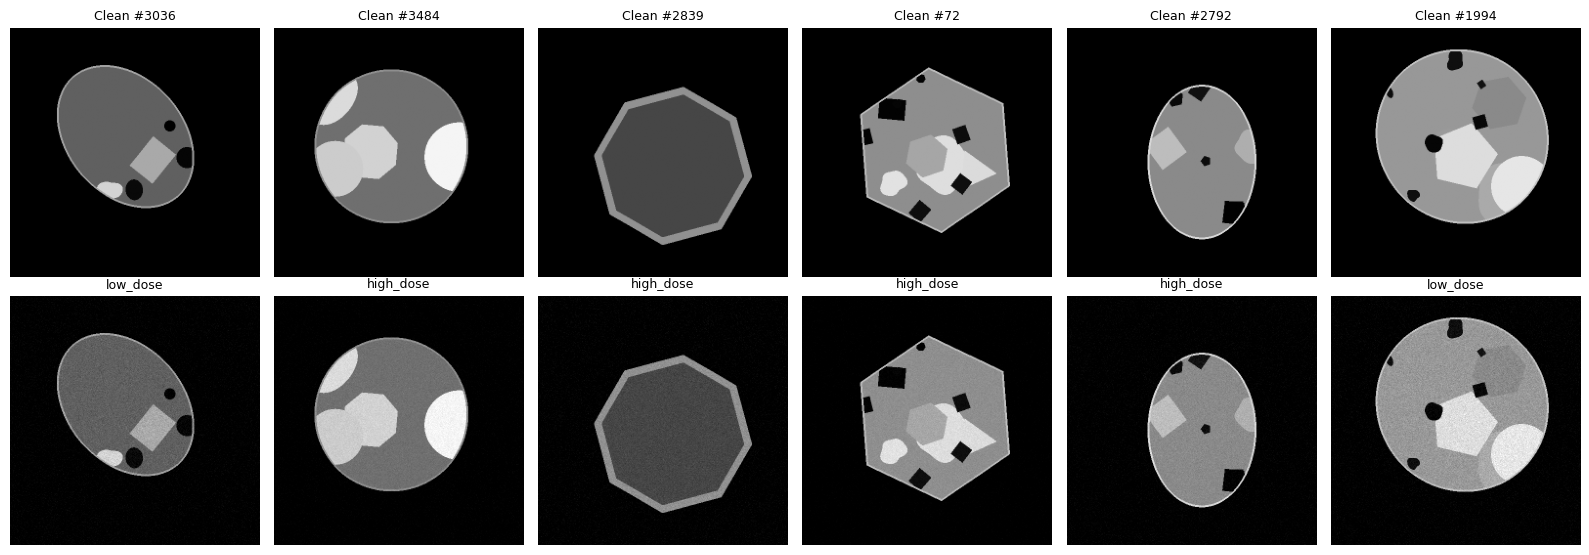

In [ ]:
# quick look: 6 random training pairs (top = clean, bottom = noisy)
look = np.random.RandomState(0).choice(idx_train, 6, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for c, i in enumerate(look):
    axes[0, c].imshow(clean_images[i], cmap="gray", vmin=0, vmax=255); axes[0, c].set_title(f"Clean #{i}", fontsize=9)
    axes[1, c].imshow(noisy_images[i], cmap="gray", vmin=0, vmax=255); axes[1, c].set_title(meta.loc[i, "dose_class"], fontsize=9)
    axes[0, c].axis("off"); axes[1, c].axis("off")
plt.tight_layout(); plt.show()

## 4. Putting the data on the GPU and define how training batches are made.

In [ ]:
clean_t = torch.from_numpy(clean_images).to(device)   # uint8, N x 256 x 256
noisy_t = torch.from_numpy(noisy_images).to(device)

def get_train_batch(batch_idx):
    xs, ys = [], []
    for i in batch_idx:
        r = np.random.randint(0, IMG_SIZE - CROP + 1)
        c = np.random.randint(0, IMG_SIZE - CROP + 1)
        x = noisy_t[i, r:r + CROP, c:c + CROP]
        y = clean_t[i, r:r + CROP, c:c + CROP]
        k = np.random.randint(4)
        if k:
            x = torch.rot90(x, k, (0, 1)); y = torch.rot90(y, k, (0, 1))
        if np.random.rand() < 0.5:
            x = torch.flip(x, (1,)); y = torch.flip(y, (1,))
        xs.append(x); ys.append(y)
    x = torch.stack(xs).unsqueeze(1).float() / 255.0
    y = torch.stack(ys).unsqueeze(1).float() / 255.0
    return x, y

@torch.no_grad()
def predict(model, noisy_uint8, bs=16):
    # denoise a stack of full 256x256 images, returns float32 numpy array in [0, 1]
    model.eval()
    outs = []
    for i in range(0, len(noisy_uint8), bs):
        x = noisy_uint8[i:i + bs].unsqueeze(1).float() / 255.0
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            o = model(x)
        outs.append(o.float().clamp(0, 1).cpu())
    return torch.cat(outs).squeeze(1).numpy()

clean_val_f = clean_images[idx_val].astype(np.float32) / 255.0
def val_psnr(model):
    pred = predict(model, noisy_t[N_TRAIN:N_TRAIN + N_VAL])
    mse = ((pred - clean_val_f) ** 2).mean(axis=(1, 2))
    return float((10 * np.log10(1.0 / np.maximum(mse, 1e-12))).mean())

## 5. The DnCNN network

In [ ]:
class DnCNN(nn.Module):
    def __init__(self, depth=17, channels=64):
        super().__init__()
        layers = [nn.Conv2d(1, channels, 3, padding=1, bias=True), nn.ReLU(inplace=True)]
        for _ in range(depth - 2):
            layers += [nn.Conv2d(channels, channels, 3, padding=1, bias=False),
                       nn.BatchNorm2d(channels), nn.ReLU(inplace=True)]
        layers += [nn.Conv2d(channels, 1, 3, padding=1, bias=False)]
        self.body = nn.Sequential(*layers)

    def forward(self, x):
        return x - self.body(x)      # noisy image minus predicted noise = denoised image

model = DnCNN(DEPTH, CHANNELS).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"DnCNN with {DEPTH} layers, {CHANNELS} channels, {n_params:,} trainable parameters")

DnCNN with 17 layers, 64 channels, 556,096 trainable parameters


## 6. Training

In [ ]:
opt = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
try:
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
except Exception:
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

steps_per_epoch = 20 if QUICK_TEST else N_TRAIN // BATCH_SIZE
start_epoch, history, best_val = 0, [], -1.0
last_path = os.path.join(CKPT_DIR, "last.pt")
best_path = os.path.join(CKPT_DIR, "best.pt")

if RESUME and os.path.exists(last_path):
    ck = torch.load(last_path, map_location=device, weights_only=False)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
    sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    start_epoch, history, best_val = ck["epoch"] + 1, ck["history"], ck["best_val"]
    print(f"Resuming from epoch {start_epoch} (best validation PSNR so far: {best_val:.2f} dB)")
else:
    print("Starting a fresh training run")

Starting a fresh training run


In [ ]:
for epoch in range(start_epoch, EPOCHS):
    t0 = time.time()
    model.train()
    perm = np.random.permutation(idx_train)
    losses = []
    for b in range(steps_per_epoch):
        x, y = get_train_batch(perm[b * BATCH_SIZE:(b + 1) * BATCH_SIZE])
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            out = model(x)
        loss = F.mse_loss(out.float(), y)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        losses.append(loss.detach())
    sched.step()

    train_loss = float(torch.stack(losses).mean())
    v = val_psnr(model)
    history.append({"epoch": epoch + 1, "train_loss": train_loss, "val_psnr": v, "lr": opt.param_groups[0]["lr"]})
    if v > best_val:
        best_val = v
        torch.save({"model": model.state_dict(), "epoch": epoch, "val_psnr": v}, best_path)
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                "scaler": scaler.state_dict(), "epoch": epoch, "history": history, "best_val": best_val}, last_path)
    print(f"epoch {epoch + 1:2d}/{EPOCHS} | loss {train_loss:.6f} | val PSNR {v:.2f} dB | best {best_val:.2f} dB | {time.time() - t0:.0f}s")

print("Training finished. Best validation PSNR:", round(best_val, 2), "dB")

epoch  1/30 | loss 0.006959 | val PSNR 38.45 dB | best 38.45 dB | 36s
epoch  2/30 | loss 0.000289 | val PSNR 37.13 dB | best 38.45 dB | 34s
epoch  3/30 | loss 0.000289 | val PSNR 38.51 dB | best 38.51 dB | 35s
epoch  4/30 | loss 0.000286 | val PSNR 37.20 dB | best 38.51 dB | 35s
epoch  5/30 | loss 0.000279 | val PSNR 38.22 dB | best 38.51 dB | 35s
epoch  6/30 | loss 0.000231 | val PSNR 41.12 dB | best 41.12 dB | 35s
epoch  7/30 | loss 0.000099 | val PSNR 43.64 dB | best 43.64 dB | 35s
epoch  8/30 | loss 0.000079 | val PSNR 43.77 dB | best 43.77 dB | 35s
epoch  9/30 | loss 0.000064 | val PSNR 43.16 dB | best 43.77 dB | 35s
epoch 10/30 | loss 0.000066 | val PSNR 43.34 dB | best 43.77 dB | 35s
epoch 11/30 | loss 0.000062 | val PSNR 44.54 dB | best 44.54 dB | 35s
epoch 12/30 | loss 0.000036 | val PSNR 47.55 dB | best 47.55 dB | 35s
epoch 13/30 | loss 0.000035 | val PSNR 44.97 dB | best 47.55 dB | 35s
epoch 14/30 | loss 0.000035 | val PSNR 47.95 dB | best 47.95 dB | 35s
epoch 15/30 | loss 0

## 7. Results

In [1]:
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
METHOD_ORDER = ["Noisy input", "Gaussian filter", "Median filter", "Non-local means", "DnCNN (CNN)"]
COLORS = {"Noisy input": "#8a8984", "DnCNN (CNN)": "#2a78d6", "Gaussian filter": "#eb6834",
          "Median filter": "#1baf7a", "Non-local means": "#eda100"}

def style_ax(ax):
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(GRID)
    ax.tick_params(which="both", colors=INK2, labelsize=9)
    ax.yaxis.grid(True, color=GRID, linewidth=0.7); ax.set_axisbelow(True)
    ax.xaxis.label.set_color(INK2); ax.yaxis.label.set_color(INK2)

hist = pd.DataFrame(history)
best_row = hist.loc[hist["val_psnr"].idxmax()]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), facecolor=SURFACE)
axes[0].plot(hist["epoch"], hist["train_loss"], color=COLORS["DnCNN (CNN)"], lw=2)
axes[0].set_yscale("log"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Training loss (mean squared error)")
axes[0].set_title("Training loss - lower is better", loc="left", fontsize=11, color=INK)
axes[1].plot(hist["epoch"], hist["val_psnr"], color=COLORS["DnCNN (CNN)"], lw=2)
axes[1].scatter([best_row["epoch"]], [best_row["val_psnr"]], s=40, color=COLORS["DnCNN (CNN)"], zorder=3, edgecolor=SURFACE, linewidth=1.5)
axes[1].annotate(f"best {best_row['val_psnr']:.2f} dB", (best_row["epoch"], best_row["val_psnr"]), textcoords="offset points",
                 xytext=(-10, 0), ha="right", va="center", fontsize=9, color=INK)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Validation PSNR (dB)")
axes[1].set_title("Validation image quality - higher is better", loc="left", fontsize=11, color=INK)
for ax in axes:
    style_ax(ax)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "fig1_training_curves.png"), dpi=150, facecolor=SURFACE)
plt.show()
hist.to_csv(os.path.join(RESULTS_DIR, "training_history.csv"), index=False)

NameError: name 'pd' is not defined

## 8. Testing : Denoising the 400 test images with the trained network

In [ ]:
ck = torch.load(best_path, map_location=device, weights_only=False)
model.load_state_dict(ck["model"])
print(f"Loaded the best checkpoint (epoch {ck['epoch'] + 1}, validation PSNR {ck['val_psnr']:.2f} dB)")
t0 = time.time()
dncnn_test = predict(model, noisy_t[N_TRAIN + N_VAL:])
print(f"Denoised {len(dncnn_test)} test images in {time.time() - t0:.1f}s")

Loaded the best checkpoint (epoch 29, validation PSNR 50.38 dB)
Denoised 400 test images in 3.7s


## 9. Classical filters for comparison

In [ ]:
clean_test = clean_images[idx_test].astype(np.float32) / 255.0
noisy_test = noisy_images[idx_test].astype(np.float32) / 255.0
clean_val = clean_images[idx_val].astype(np.float32) / 255.0
noisy_val = noisy_images[idx_val].astype(np.float32) / 255.0

def evaluate(pred_stack, clean_stack):
    ps, ss = [], []
    for p, c in zip(pred_stack, clean_stack):
        p = np.clip(p, 0, 1).astype(np.float32)
        ps.append(psnr(c, p, data_range=1.0)); ss.append(ssim(c, p, data_range=1.0))
    return np.array(ps), np.array(ss)

def tune(fn, params, n=60):
    best_p, best_s = None, -1
    for p in params:
        pred = np.stack([fn(im, p) for im in noisy_val[:n]])
        s = evaluate(pred, clean_val[:n])[0].mean()
        if s > best_s:
            best_p, best_s = p, s
    return best_p

gauss = lambda im, s: gaussian_filter(im, sigma=s)
med = lambda im, s: median_filter(im, size=s)
nlm = lambda im, h: denoise_nl_means(im, h=h, sigma=0.0, patch_size=5, patch_distance=6, fast_mode=True)

best_sigma = tune(gauss, [0.5, 0.7, 0.9, 1.2, 1.5, 2.0])
best_size = tune(med, [3, 5])
best_h = tune(nlm, [0.01, 0.02, 0.03, 0.05, 0.08])
print("Best Gaussian sigma:", best_sigma, "| best median window:", best_size, "| best non-local-means strength h:", best_h)

t0 = time.time()
results = {
    "Noisy input": noisy_test,
    "Gaussian filter": np.stack([gauss(im, best_sigma) for im in noisy_test]),
    "Median filter": np.stack([med(im, best_size) for im in noisy_test]),
    "Non-local means": np.stack([nlm(im, best_h) for im in noisy_test]),
    "DnCNN (CNN)": dncnn_test,
}
print(f"Classical filters finished in {time.time() - t0:.0f}s")

Best Gaussian sigma: 0.5 | best median window: 3 | best non-local-means strength h: 0.03
Classical filters finished in 46s


## 10. Scores (PSNR and SSIM)
**PSNR** (in dB) and **SSIM** (0 to 1) both measure how close a result is to the clean image - higher is better. Mean and standard deviation are over the 400 test images.

In [ ]:
per_psnr, per_ssim = {}, {}
for m in METHOD_ORDER:
    per_psnr[m], per_ssim[m] = evaluate(results[m], clean_test)

summary = pd.DataFrame({
    "Method": METHOD_ORDER,
    "PSNR mean (dB)": [per_psnr[m].mean() for m in METHOD_ORDER],
    "PSNR std": [per_psnr[m].std() for m in METHOD_ORDER],
    "SSIM mean": [per_ssim[m].mean() for m in METHOD_ORDER],
    "SSIM std": [per_ssim[m].std() for m in METHOD_ORDER],
}).round(4)
summary.to_csv(os.path.join(RESULTS_DIR, "results_summary.csv"), index=False)
print("Overall results on the 400 test images:")
print(summary.to_string(index=False))

dose_test = meta.loc[idx_test, "dose_class"].values
rows = []
for d in ["low_dose", "medium_dose", "high_dose"]:
    mask = dose_test == d
    for m in METHOD_ORDER:
        rows.append({"dose_class": d, "Method": m, "n_images": int(mask.sum()),
                     "PSNR mean (dB)": per_psnr[m][mask].mean(), "SSIM mean": per_ssim[m][mask].mean()})
by_dose = pd.DataFrame(rows).round(4)
by_dose.to_csv(os.path.join(RESULTS_DIR, "results_by_dose.csv"), index=False)
print("\nPSNR (dB) by radiation dose level:")
print(by_dose.pivot(index="Method", columns="dose_class", values="PSNR mean (dB)").loc[METHOD_ORDER].to_string())

best_classical = max(["Gaussian filter", "Median filter", "Non-local means"], key=lambda m: per_psnr[m].mean())
wins = float((per_psnr["DnCNN (CNN)"] > per_psnr[best_classical]).mean() * 100)
gain = per_psnr["DnCNN (CNN)"].mean() - per_psnr["Noisy input"].mean()
print(f"\nDnCNN improves PSNR by {gain:.2f} dB on average over the noisy input.")
print(f"DnCNN beats the best classical filter ({best_classical}) on {wins:.1f}% of the test images.")

pd.DataFrame({"sample_id": meta.loc[idx_test, "sample_id"].values, "dose_class": dose_test,
              **{f"psnr_{m}": per_psnr[m] for m in METHOD_ORDER},
              **{f"ssim_{m}": per_ssim[m] for m in METHOD_ORDER}}).round(4).to_csv(
    os.path.join(RESULTS_DIR, "per_image_results.csv"), index=False)

Overall results on the 400 test images:
         Method  PSNR mean (dB)  PSNR std  SSIM mean  SSIM std
    Noisy input         37.9340    2.4622     0.8090    0.0871
Gaussian filter         37.4430    1.5424     0.8571    0.0709
  Median filter         41.3823    2.5742     0.9641    0.0192
Non-local means         45.5613    2.0228     0.9100    0.0583
    DnCNN (CNN)         50.2787    1.8681     0.9982    0.0007

PSNR (dB) by radiation dose level:
dose_class       high_dose  low_dose  medium_dose
Method                                           
Noisy input        38.5955   36.7034      37.4632
Gaussian filter    37.6697   36.9845      37.3138
Median filter      41.7308   40.2770      41.5336
Non-local means    45.9304   44.8384      45.3305
DnCNN (CNN)        50.8822   48.9191      50.0563

DnCNN improves PSNR by 12.34 dB on average over the noisy input.
DnCNN beats the best classical filter (Non-local means) on 100.0% of the test images.


## 11. Figures for the paper

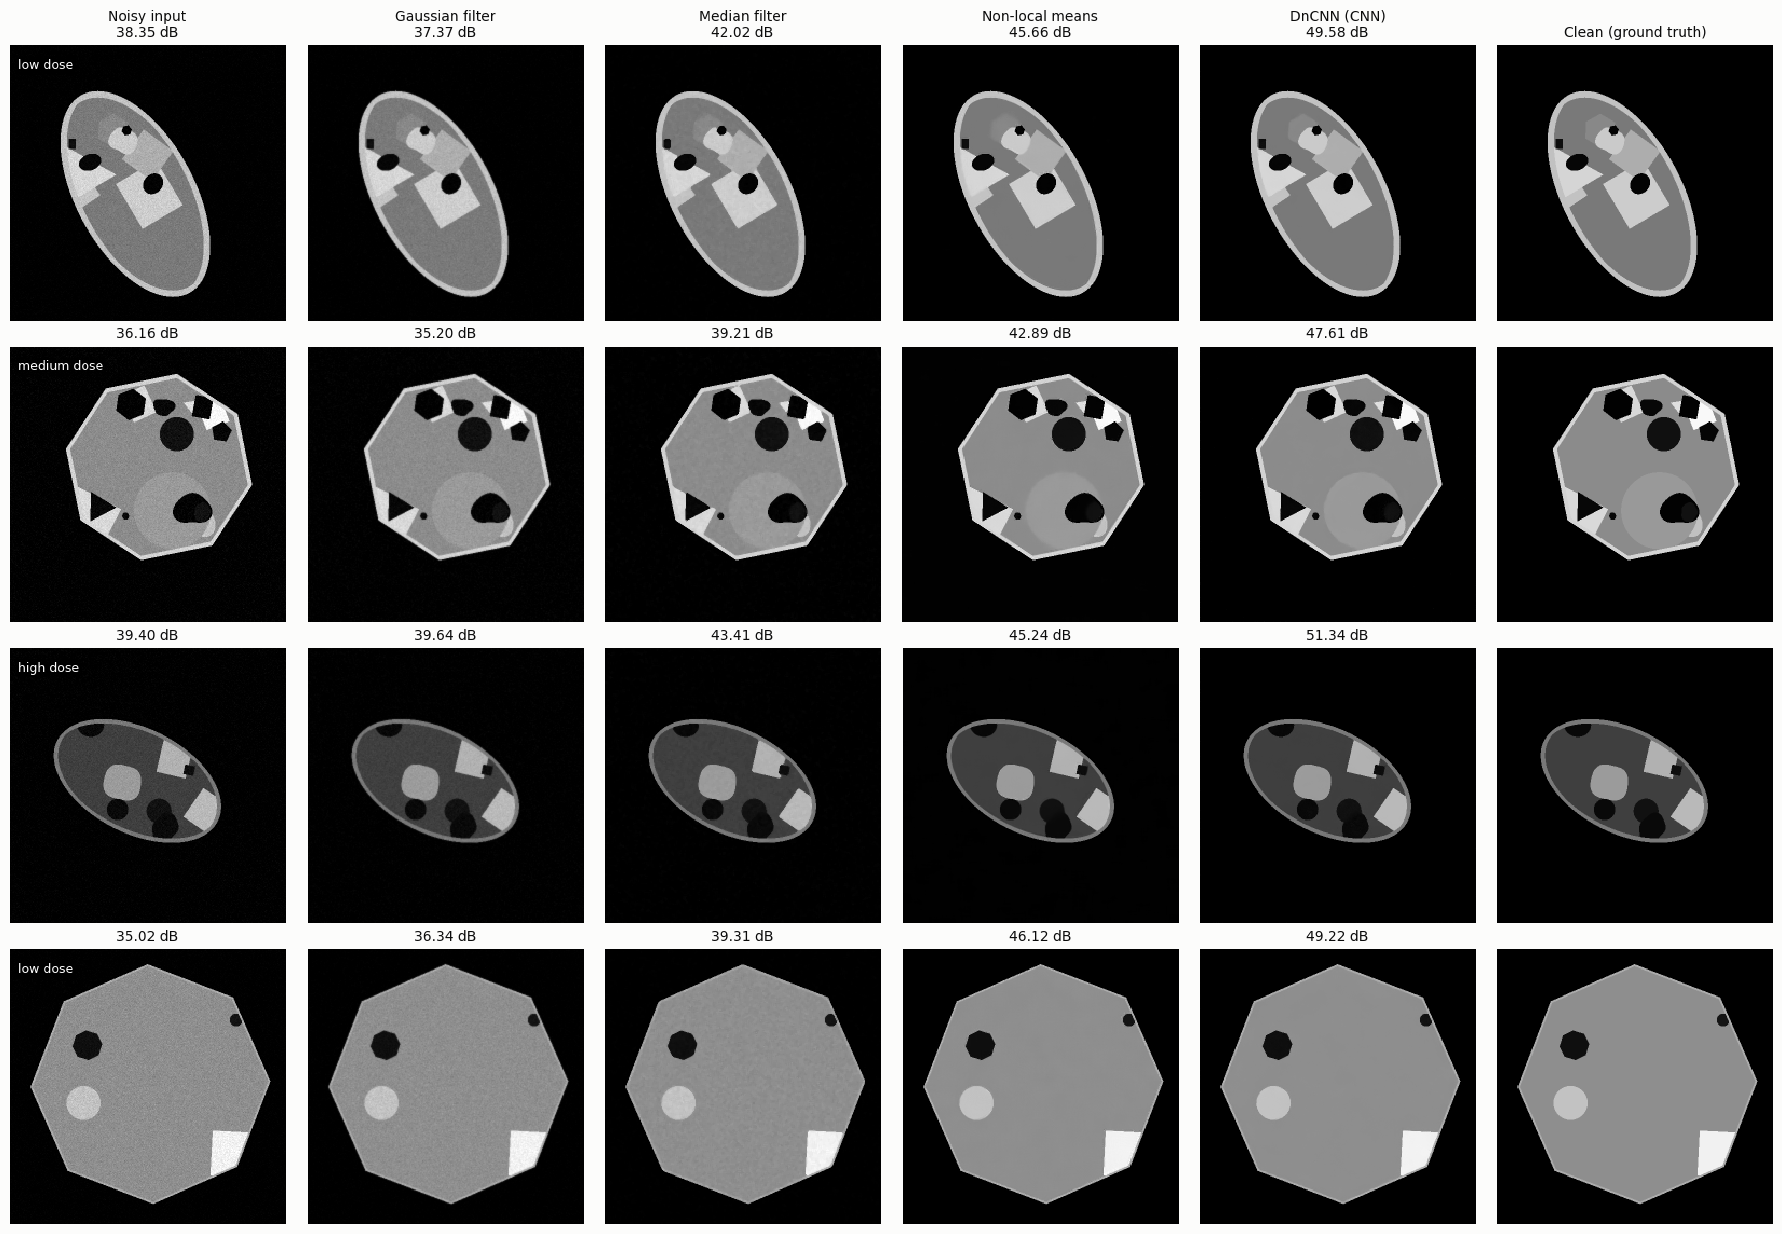

In [ ]:
# Figure 2: side-by-side images (one low-, medium- and high-dose example, plus a second low-dose one)
pick = []
for d in ["low_dose", "medium_dose", "high_dose"]:
    w = np.where(dose_test == d)[0]
    if len(w):
        pick.append(int(w[0]))
w = np.where(dose_test == "low_dose")[0]
if len(w) > 1:
    pick.append(int(w[1]))

names = METHOD_ORDER + ["Clean (ground truth)"]
fig, axes = plt.subplots(len(pick), 6, figsize=(18, 3.1 * len(pick)), facecolor=SURFACE)
axes = np.atleast_2d(axes)
for r, k in enumerate(pick):
    imgs = [results[m][k] for m in METHOD_ORDER] + [clean_test[k]]
    for c, im in enumerate(imgs):
        ax = axes[r, c]
        ax.imshow(np.clip(im, 0, 1), cmap="gray", vmin=0, vmax=1, interpolation="nearest"); ax.axis("off")
        ttl = names[c] if r == 0 else ""
        sub = f"{per_psnr[names[c]][k]:.2f} dB" if c < 5 else ""
        ax.set_title((ttl + "\n" + sub).strip(), fontsize=10, color=INK)
    axes[r, 0].text(0.03, 0.95, dose_test[k].replace("_", " "), transform=axes[r, 0].transAxes, color="white",
                    fontsize=9, va="top", bbox=dict(facecolor="black", alpha=0.55, pad=2, edgecolor="none"))
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "fig2_visual_comparison.png"), dpi=130, facecolor=SURFACE)
plt.show()

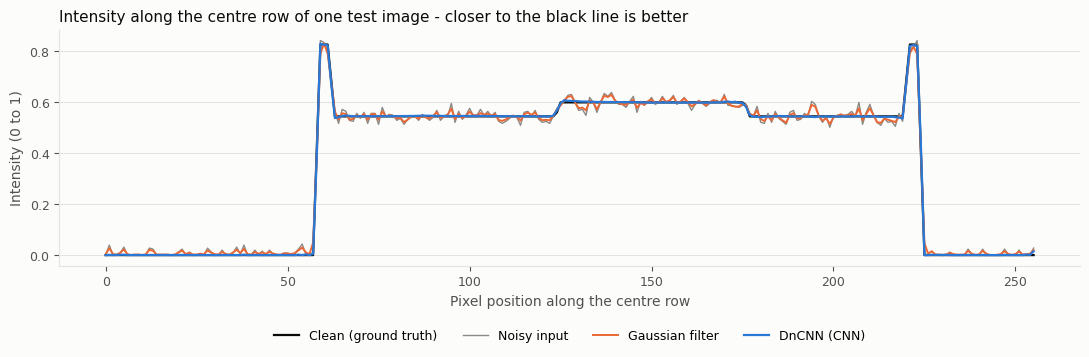

In [ ]:
# Figure 3: intensity along one horizontal line through a test image (a "line profile")
k = pick[1] if len(pick) > 1 else 0
row = IMG_SIZE // 2
fig, ax = plt.subplots(figsize=(11, 3.8), facecolor=SURFACE)
ax.plot(clean_test[k][row], color=INK, lw=1.6, label="Clean (ground truth)")
ax.plot(results["Noisy input"][k][row], color=COLORS["Noisy input"], lw=1.0, label="Noisy input")
ax.plot(results["Gaussian filter"][k][row], color=COLORS["Gaussian filter"], lw=1.4, label="Gaussian filter")
ax.plot(results["DnCNN (CNN)"][k][row], color=COLORS["DnCNN (CNN)"], lw=1.6, label="DnCNN (CNN)")
ax.set_xlabel("Pixel position along the centre row"); ax.set_ylabel("Intensity (0 to 1)")
ax.set_title("Intensity along the centre row of one test image - closer to the black line is better", loc="left", fontsize=11, color=INK)
ax.legend(frameon=False, fontsize=9, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.22))
style_ax(ax)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "fig3_line_profile.png"), dpi=150, facecolor=SURFACE, bbox_inches="tight")
plt.show()

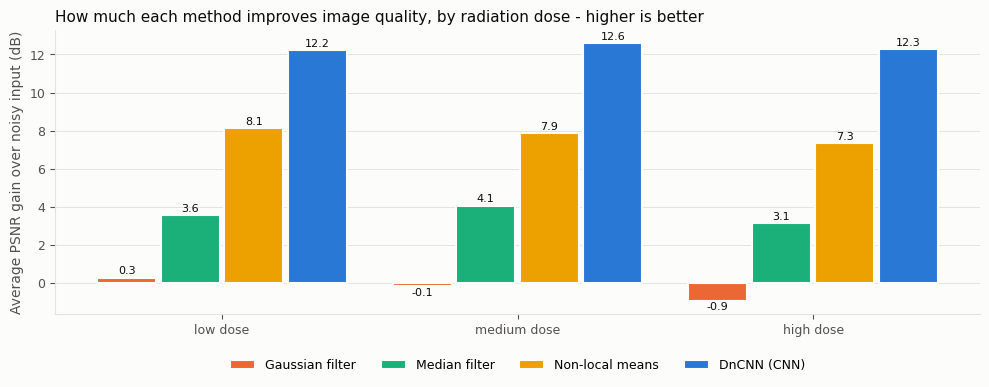

In [ ]:
# Figure 4: average PSNR improvement over the noisy input, split by radiation dose
dose_names = ["low_dose", "medium_dose", "high_dose"]
shown = ["Gaussian filter", "Median filter", "Non-local means", "DnCNN (CNN)"]
fig, ax = plt.subplots(figsize=(10, 4), facecolor=SURFACE)
width = 0.2
for j, m in enumerate(shown):
    vals = [(per_psnr[m][dose_test == d] - per_psnr["Noisy input"][dose_test == d]).mean() for d in dose_names]
    xs = np.arange(len(dose_names)) + (j - 1.5) * (width + 0.015)
    ax.bar(xs, vals, width=width, color=COLORS[m], label=m, edgecolor=SURFACE, linewidth=1.5)
    for x, v in zip(xs, vals):
        ax.text(x, v + (0.08 if v >= 0 else -0.08), f"{v:.1f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=8, color=INK)
ax.set_xticks(np.arange(len(dose_names))); ax.set_xticklabels([d.replace("_", " ") for d in dose_names])
ax.set_ylabel("Average PSNR gain over noisy input (dB)")
ax.set_title("How much each method improves image quality, by radiation dose - higher is better", loc="left", fontsize=11, color=INK)
ax.legend(frameon=False, fontsize=9, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
style_ax(ax)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "fig4_gain_by_dose.png"), dpi=150, facecolor=SURFACE, bbox_inches="tight")
plt.show()

## 12. Saving Data

In [ ]:
run_info = {
    "dataset": {"n_total": N_TOTAL, "n_train": N_TRAIN, "n_val": N_VAL, "n_test": N_TEST, "image_size": IMG_SIZE, "seed": SEED},
    "model": {"name": "DnCNN", "depth": DEPTH, "channels": CHANNELS, "parameters": int(n_params)},
    "training": {"epochs": EPOCHS, "batch_size": BATCH_SIZE, "crop": CROP, "learning_rate": LR, "optimizer": "Adam + cosine decay",
                 "loss": "MSE", "best_val_psnr_db": round(float(best_val), 3), "quick_test": QUICK_TEST},
    "classical_baselines": {"gaussian_sigma": best_sigma, "median_window": best_size, "nlm": f"patch 5, distance 6, h = {best_h}"},
    "test_results": summary.to_dict(orient="records"),
    "dncnn_beats_best_classical_percent": round(wins, 1),
    "best_classical": best_classical,
}
with open(os.path.join(RESULTS_DIR, "run_info.json"), "w") as f:
    json.dump(run_info, f, indent=2)
shutil.copy(best_path, os.path.join(RESULTS_DIR, "dncnn_best_model.pt"))

zip_path = shutil.make_archive(os.path.join(WORK_DIR, "results_bundle_quick" if QUICK_TEST else "results_bundle"), "zip", RESULTS_DIR)
print("Saved:", zip_path)
print("Files inside:", sorted(os.listdir(RESULTS_DIR)))
try:
    from google.colab import files
    files.download(zip_path)
except Exception as e:
    print("Download skipped (not running in Colab):", e)

Saved: /content/ct_denoising/results_bundle.zip
Files inside: ['dncnn_best_model.pt', 'fig1_training_curves.png', 'fig2_visual_comparison.png', 'fig3_line_profile.png', 'fig4_gain_by_dose.png', 'per_image_results.csv', 'results_by_dose.csv', 'results_summary.csv', 'run_info.json', 'training_history.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>